# 00 — Pipeline complet sur Colab (dans l'ordre d'exécution)
**Exécution > Modifier le type d'exécution > GPU T4**, puis lancer les cellules **une par une, dans l'ordre**.

Principe (leçon de nos essais) : tout le travail se fait sur le **disque local de Colab** (rapide et fiable).
Google Drive ne sert qu'à **reprendre** (étape 0) et à **sauvegarder à la fin** (étape 10) : écrire directement sur Drive
pendant les calculs a fait perdre des fichiers lors des réinitialisations de session.

| Étape | Durée (T4) |
|---|---|
| 1. Installation · 2. Données · 3. Préparation | ~5 min |
| 4. Baseline | ~3 min |
| 5. Entraînement (4 rangs) | ~55 min |
| 6. Génération (16 versions) | ~45 min |
| 7. Évaluation · 8. Tableaux · 9. Contrôle visuel | ~8 min |
| 10. Sauvegarde sur Drive | ~3 min |

## 1. Installation : code, dépendances, Google Drive

In [ ]:
import os, sys, subprocess
from google.colab import drive
drive.mount('/content/drive')
D = '/content/drive/MyDrive/lora-zellige'      # dossier de sauvegarde finale
os.chdir('/content')
if not os.path.exists('lora-zellige'):
    subprocess.run(['git', 'clone', '-q', 'https://github.com/braziyass/lora-zellige.git'], check=True)
os.chdir('/content/lora-zellige')
subprocess.run(['git', 'pull', '-q'], check=True)
subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', '-r', 'requirements.txt'], check=True)
# Dossiers de travail LOCAUX (on supprime d'éventuels anciens liens vers Drive)
for sub in ['data/raw', 'data/processed', 'outputs', 'results/generations']:
    if os.path.islink(sub):
        os.unlink(sub)
    os.makedirs(sub, exist_ok=True)
import torch
print('GPU :', torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'AUCUN — activez le GPU T4')

### 1 bis. (Optionnel) Reprendre une session : récupérer les LoRA déjà sauvegardées
À lancer seulement si une sauvegarde existe dans `MyDrive/lora-zellige/final/` : l'étape 5 sautera alors les rangs déjà entraînés.

In [ ]:
if os.path.exists(f'{D}/final/loras'):
    !cp -r {D}/final/loras outputs/
    !find outputs/loras -name '*.safetensors' | wc -l
else:
    print('Aucune sauvegarde trouvée : on part de zéro.')

## 2. Téléchargement des images (Wikimedia Commons, licences libres)

In [ ]:
for cat, n in [('Zellij in Morocco', 80), ('Zellij fountains in Morocco', 30)]:
    !python data/download_commons.py --category "{cat}" --limit {n} --sources /content/sources_downloaded.csv
print(len(os.listdir('data/raw')), 'images dans data/raw')

### 2 bis. (Optionnel) Planches contact — pour choisir et légender les images
La sélection et les légendes sont déjà dans `data/sources.csv` (colonnes `keep` et `caption`).

In [ ]:
import pandas as pd, matplotlib.pyplot as plt
from PIL import Image
src = pd.read_csv('/content/sources_downloaded.csv')
for start in range(0, len(src), 12):
    fig, axes = plt.subplots(3, 4, figsize=(16, 12))
    for ax in axes.flat: ax.axis('off')
    for ax, (i, r) in zip(axes.flat, src.iloc[start:start + 12].iterrows()):
        ax.imshow(Image.open(f"data/raw/{r['file']}").convert('RGB')); ax.set_title(f"#{i} {r['file']}", fontsize=9)
    plt.tight_layout(); plt.show()

## 3. Préparation du jeu de données
Doit afficher **`train=16  test=5`** et `'introuvable': 0`. Sinon, relancer l'étape 2.

In [ ]:
!python -m src.prepare_data --config configs/base.yaml

## 4. Baseline : le modèle de base, sans LoRA (le « avant »)

In [ ]:
!python -m src.generate --config configs/base.yaml --base_only

## 5. Entraînement : rangs 4, 8, 16, 32 (checkpoints 250 / 500 / 1000 / 1500)
Les rangs déjà entraînés sont sautés. Pour aller plus vite : `--ranks 4 16`.

In [ ]:
!python -m src.sweep --sweep configs/sweep.yaml

## 6. Génération : les 16 versions, mêmes prompts et mêmes graines que la baseline

In [ ]:
!python -m src.generate --config configs/base.yaml

## 7. Évaluation : CLIP-score, similarité au domaine, mémorisation, diversité, coût

In [ ]:
!python -m src.evaluate --config configs/base.yaml

## 8. Tableaux de résultats (rang × étapes)

In [17]:
import pandas as pd
s = pd.read_csv('results/metrics_summary.csv')
for cat, m in [('composition', 'clip_score'), ('in_domain', 'clip_score'), ('all', 'domain_sim'), ('held_out', 'domain_sim'),
               ('all', 'memorization_ratio'), ('all', 'copy_rate'), ('all', 'diversity')]:
    print(f'== {cat} / {m}')
    print(s[s.category == cat].pivot_table(index='rank', columns='step', values=m).round(3).to_string(), '\n')
print(s[(s.category == 'all') & (s.step == 1500)][['rank', 'train_time_min', 'peak_vram_gb', 'lora_size_mb']].to_string(index=False))

== composition / clip_score
step    0       250     500     1000    1500
rank                                        
0     28.591     NaN     NaN     NaN     NaN
4        NaN  27.677  28.036  28.868  27.798
8        NaN  28.390  28.681  28.382  28.219
16       NaN  28.083  28.610  29.037  28.212
32       NaN  29.041  28.695  29.088  29.576 

== in_domain / clip_score
step    0       250     500     1000    1500
rank                                        
0     29.022     NaN     NaN     NaN     NaN
4        NaN  28.302  30.113  28.871  28.844
8        NaN  29.000  29.089  30.186  28.475
16       NaN  28.261  27.513  30.380  31.009
32       NaN  27.658  27.062  27.458  28.018 

== all / domain_sim
step  0      250    500    1000   1500
rank                                  
0     0.66    NaN    NaN    NaN    NaN
4      NaN  0.670  0.682  0.682  0.683
8      NaN  0.674  0.686  0.686  0.701
16     NaN  0.677  0.675  0.700  0.694
32     NaN  0.672  0.691  0.696  0.718 

== held_out / dom

## 9. Contrôle visuel : grilles et comparaison base / LoRA

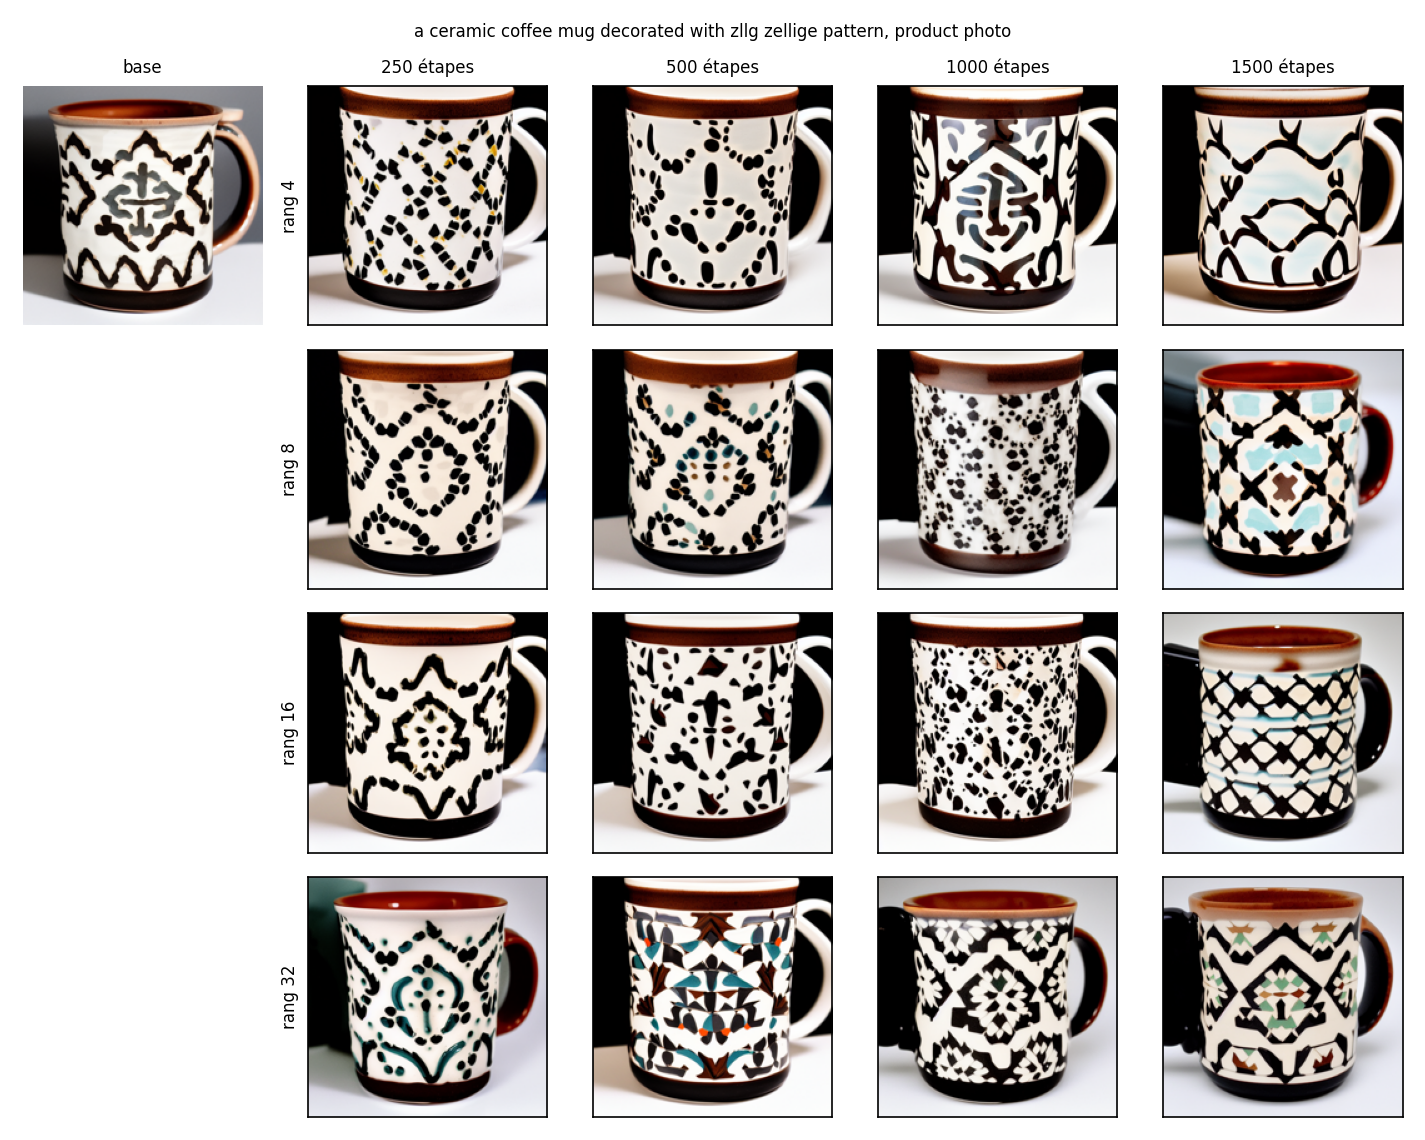

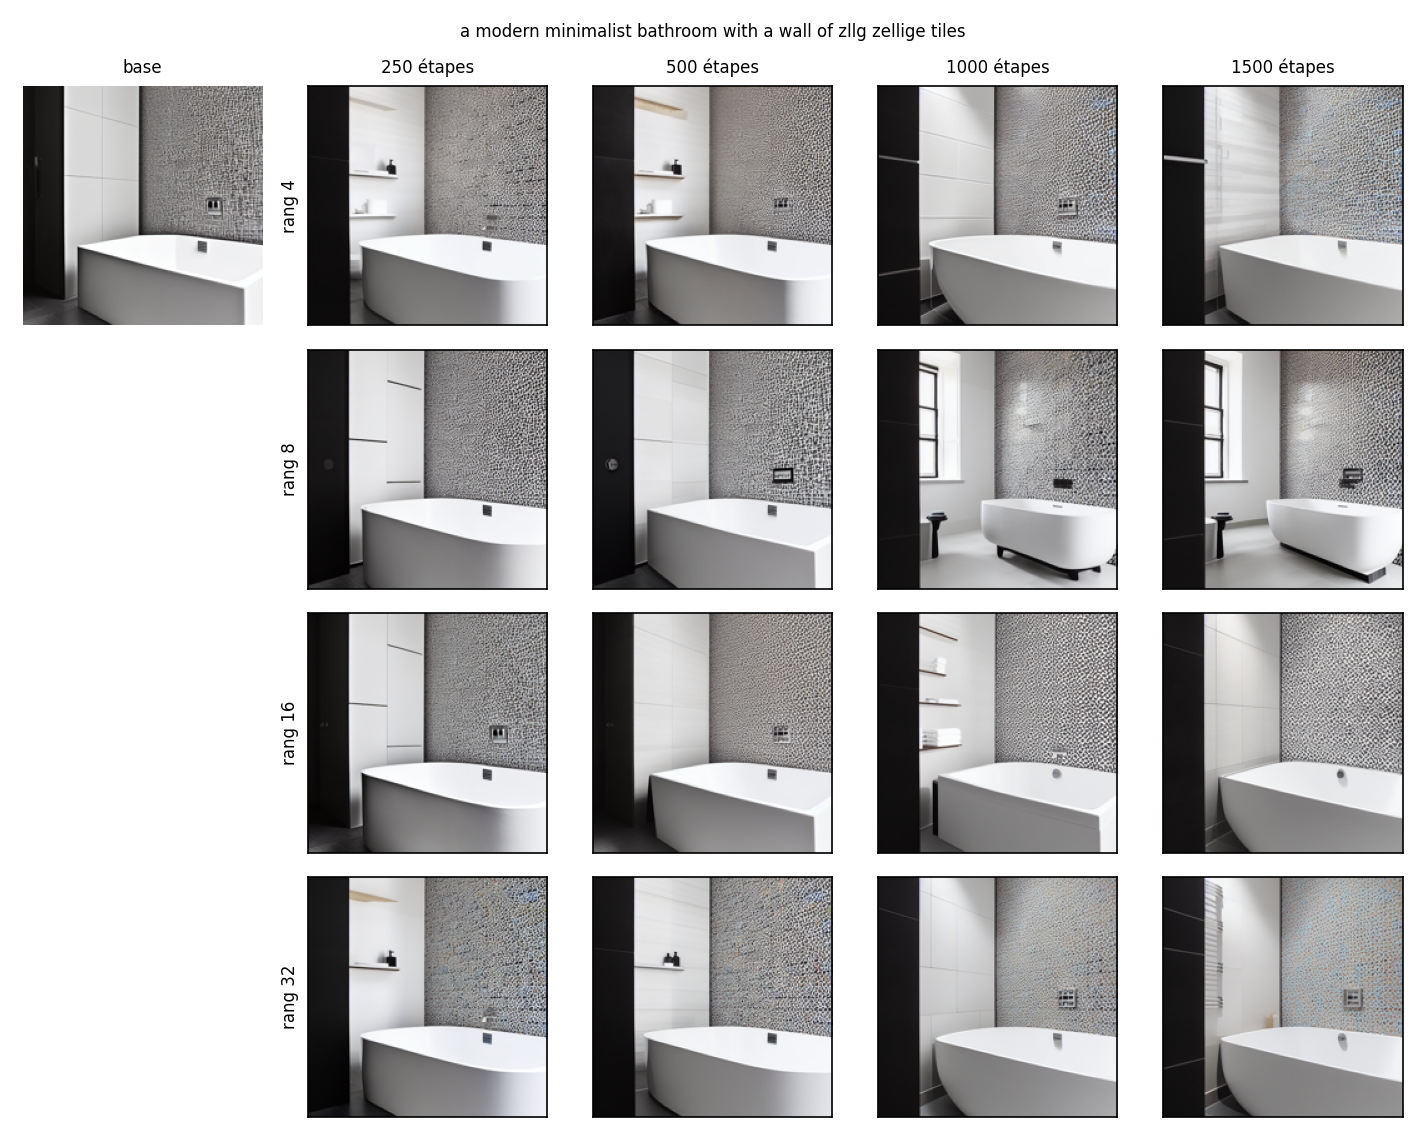

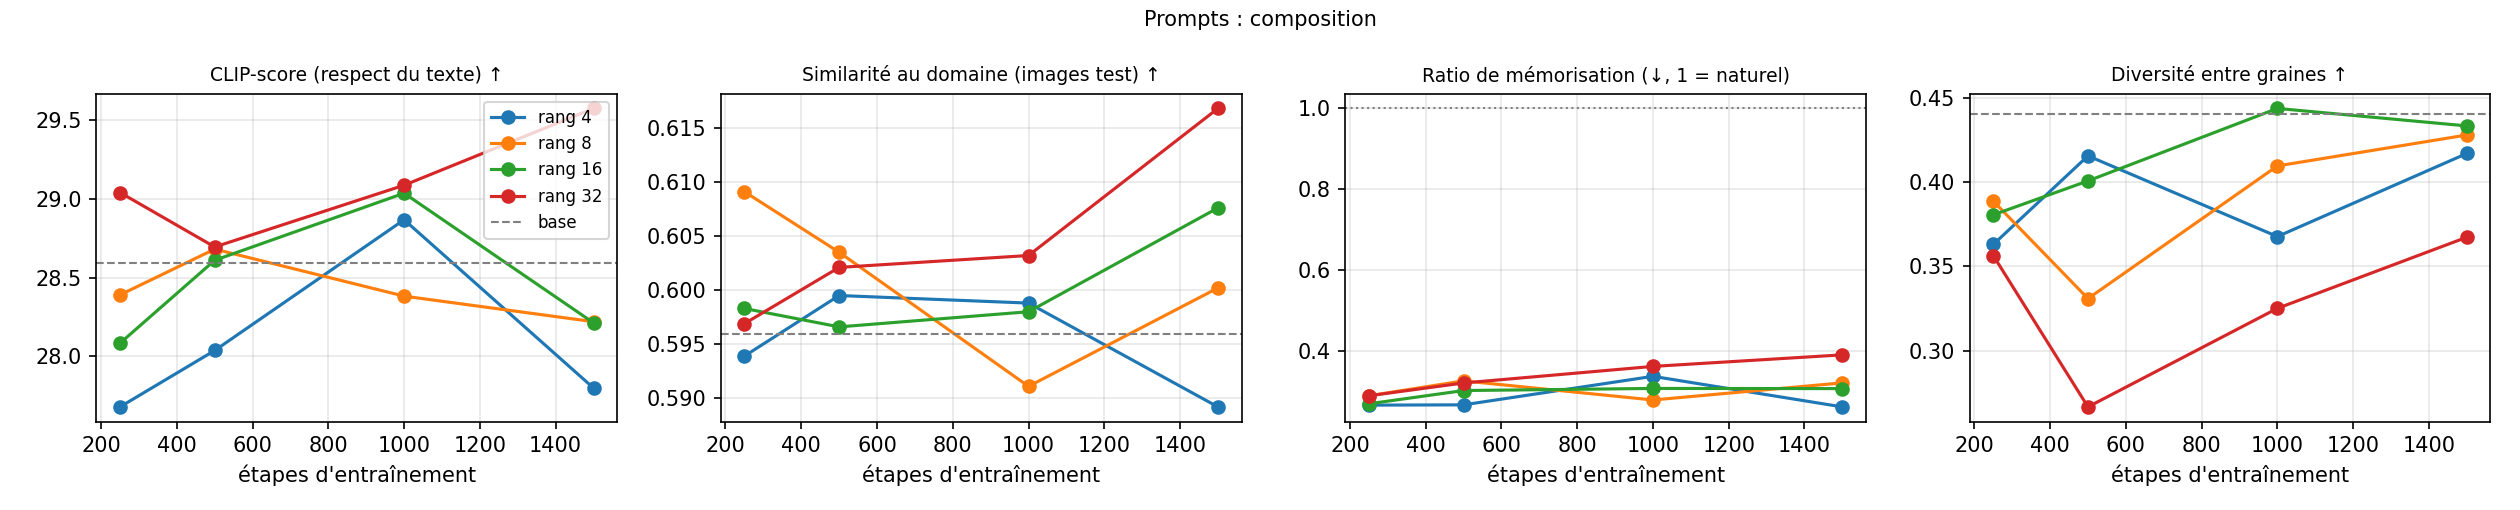

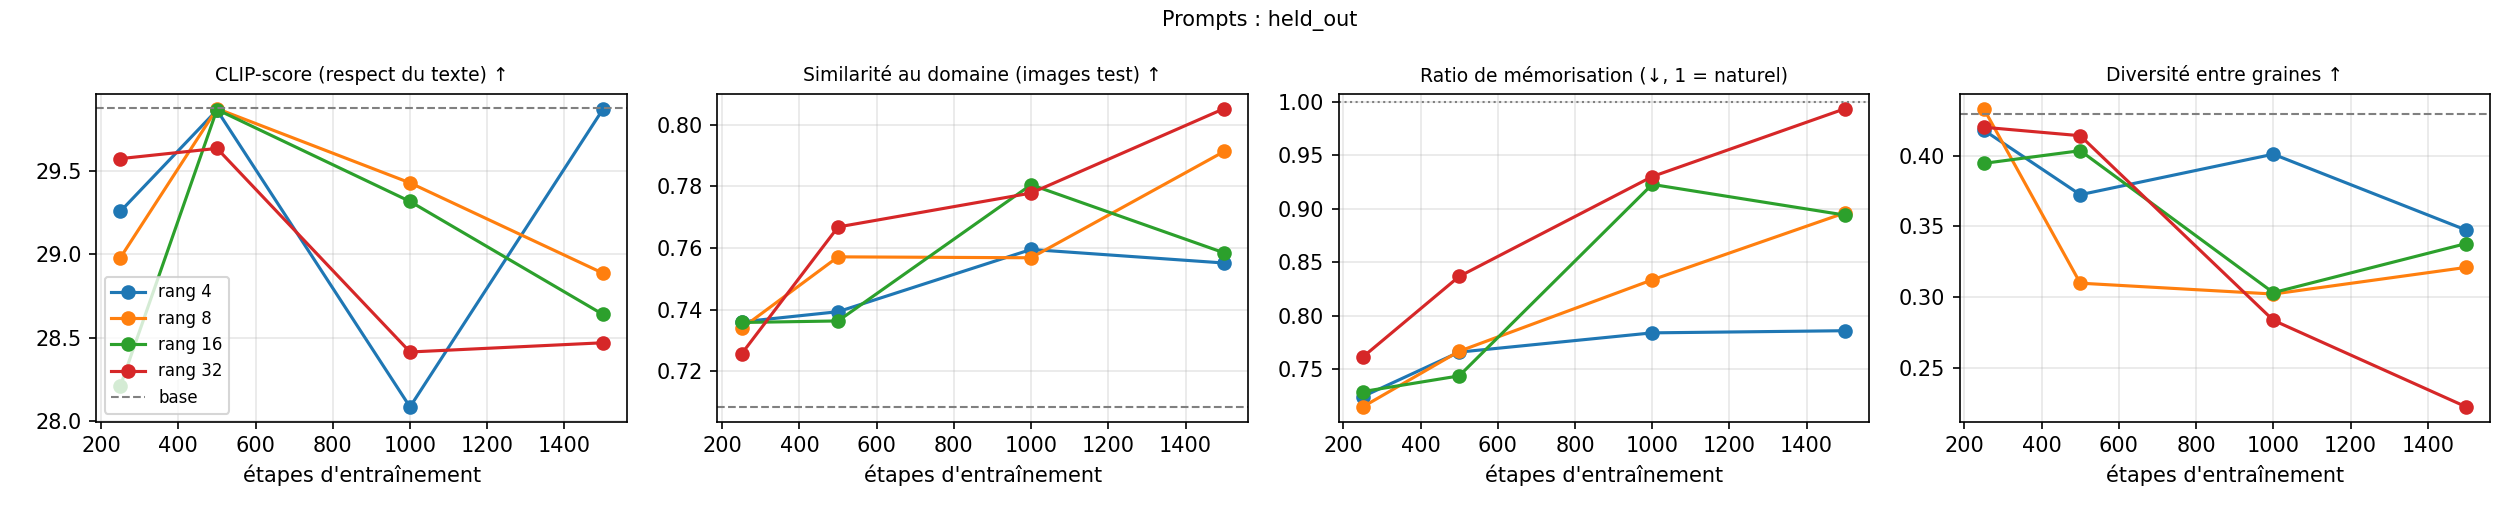

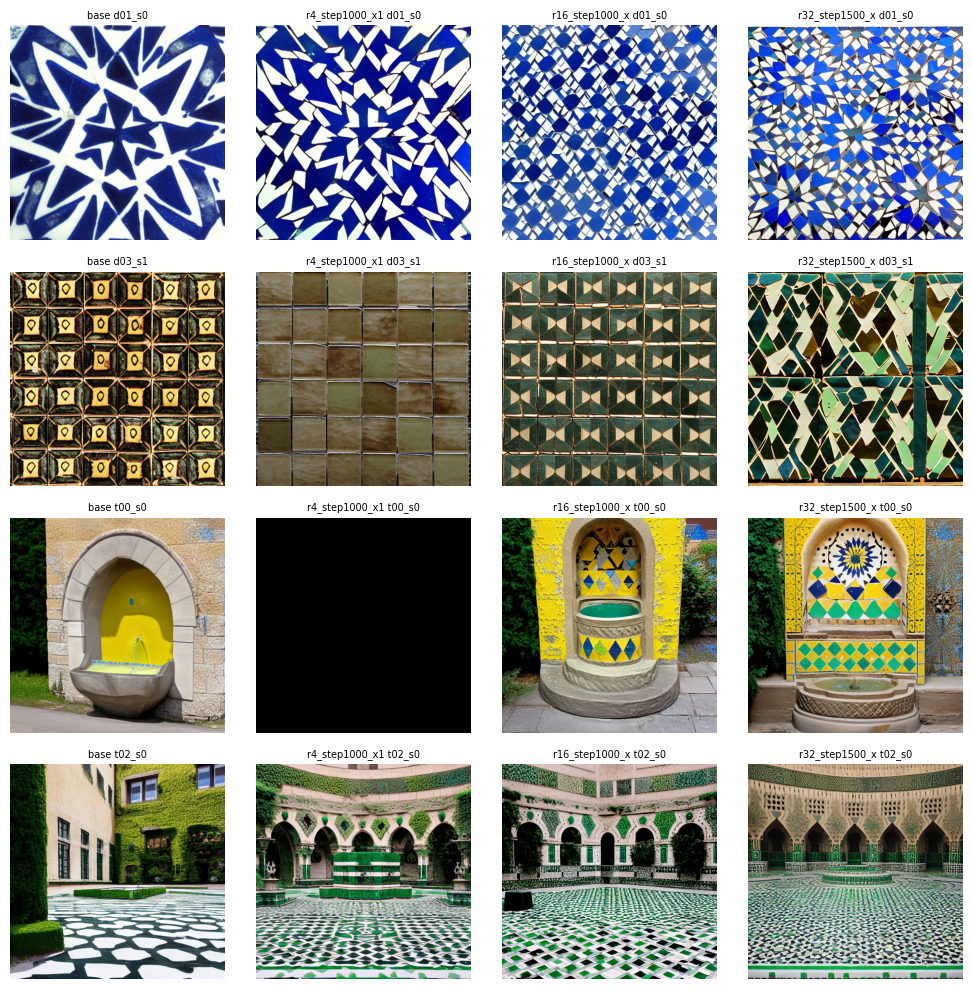

In [18]:
from IPython.display import Image as I, display
import matplotlib.pyplot as plt
from PIL import Image as P
for f in ['grid_c01_s0', 'grid_c02_s0', 'curves_composition', 'curves_held_out']:
    display(I(f'results/figures/{f}.png', width=700))
G = 'results/generations'
C = ['base', 'r4_step1000_x1.0', 'r16_step1000_x1.0', 'r32_step1500_x1.0']
R = ['d01_s0', 'd03_s1', 't00_s0', 't02_s0']
fig, ax = plt.subplots(len(R), len(C), figsize=(10, 10))
for i, r in enumerate(R):
    for j, c in enumerate(C):
        ax[i][j].imshow(P.open(f'{G}/{c}/{r}.png')); ax[i][j].axis('off'); ax[i][j].set_title(f'{c[:14]} {r}', fontsize=7)
plt.tight_layout()
fig.savefig('results/figures/comparison_base_vs_lora.png', dpi=110, bbox_inches='tight')
plt.show()

## 10. Sauvegarde finale sur Google Drive (+ téléchargement des figures)
À lancer **en dernier**, une fois les étapes 7 à 9 réussies. Tout va dans `MyDrive/lora-zellige/final/`.

In [ ]:
import shutil
os.makedirs(f'{D}/final', exist_ok=True)
!cp -r outputs/loras results/*.csv results/*.json results/figures {D}/final/
!cd results && zip -qr {D}/final/generations.zip generations
!find {D}/final/loras -name '*.safetensors' | wc -l
!du -sh {D}/final/*
shutil.make_archive('/content/figures', 'zip', 'results/figures')
from google.colab import files
files.download('/content/figures.zip')
drive.flush_and_unmount()   # force Drive à finir la synchronisation

## 11. (Optionnel) Démo interactive
Ouvre un lien public `gradio.live` : prompt, intensité de la LoRA, comparaison avant / après.

In [ ]:
!python demo/app.py --share